<a href="https://colab.research.google.com/github/ignaciovelasco/Equipo1_IA/blob/main/Assignments/Final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final project: Intelligent Medical Image Classification

**Goal:** Train a CNN to classify MRI images into four groups: **glioma, meningioma, no tumor, and pituitary tumor**.

**Team Number:** #1

**Class Schedule:** N3

**Team members:**

Ignacio Alberto Velasco García ID: 2177890

Dulce Aidé Vega del Angel ID: 2068193

Odalys Sherlyn Correa Galván ID: 2177754

Jonathan Sánchez Ramírez ID: 2111769

Gael Alejandro Reyes Zaragoza ID: 2178099

**Dataset:** [Brain Tumor MRI Dataset — Masoud Nickparvar (Kaggle)](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset).

## 1. Import Libraries

This section imports the libraries required for image processing, dataset management, neural network training, and model evaluation.

It also defines the four classification categories and the main training parameters, including image size, batch size, and number of epochs.

In [ ]:
# Install the library used to download the dataset
%pip -q install kagglehub

# Libraries for dataset management and image processing
from pathlib import Path
import hashlib
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Libraries for training and evaluating the CNN
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from google.colab import files

# Define the classification categories
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]

# Define the training parameters
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10

# Set random seeds for reproducible results
np.random.seed(42)
tf.random.set_seed(42)

## 2. Download and Clean the Dataset

The Brain Tumor MRI Dataset is downloaded from Kaggle. It contains MRI images organized into four categories: glioma, meningioma, no tumor, and pituitary tumor.

The dataset is inspected to remove corrupted, excessively small, and duplicate images. This process improves data quality and helps prevent identical images from appearing in both training and testing.

In [ ]:
# Download the Brain Tumor MRI Dataset from Kaggle
data_dir = Path(
    kagglehub.dataset_download(
        "masoudnickparvar/brain-tumor-mri-dataset"
    )
)

# Generate a fingerprint to identify duplicate images
def image_hash(path):
    with Image.open(path) as image:
        if min(image.size) < 32:
            raise ValueError("Image is too small")

        pixels = image.convert("L").resize((128, 128)).tobytes()

    return hashlib.sha256(pixels).hexdigest()


# Store valid image paths and their labels
image_paths = []
labels = []
known_hashes = set()

invalid_count = 0
duplicate_count = 0

# Check image quality and remove duplicates
for split in ("Training", "Testing"):
    for label, class_name in enumerate(CLASS_NAMES):
        folder = data_dir / split / class_name

        if not folder.is_dir():
            raise FileNotFoundError(f"Folder not found: {folder}")

        for path in sorted(folder.iterdir()):
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue

            try:
                fingerprint = image_hash(path)
            except (OSError, ValueError):
                invalid_count += 1
                continue

            if fingerprint in known_hashes:
                duplicate_count += 1
                continue

            known_hashes.add(fingerprint)
            image_paths.append(str(path))
            labels.append(label)

# Display dataset information
print(f"Valid images: {len(image_paths)}")
print(f"Invalid images: {invalid_count}")
print(f"Duplicates removed: {duplicate_count}")

for i, name in enumerate(CLASS_NAMES):
    print(f"{name}: {labels.count(i)}")

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Valid images: 6878
Invalid images: 0
Duplicates removed: 322
glioma: 1779
meningioma: 1684
notumor: 1657
pituitary: 1758


## 3. Split and Prepare the Images

The dataset is divided into 80% training data and 20% testing data. The training set is used to teach the model, while the testing set measures its performance on images that were not used during training.

All images are resized to 224 × 224 pixels and converted to RGB format to match the input requirements of MobileNetV2.

Pixel normalization is performed inside the neural network.

In [ ]:
# Split the dataset into 80% training and 20% testing
train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print(f"Training images: {len(train_paths)}")
print(f"Testing images: {len(test_paths)}")


# Load, resize, and convert images to RGB
def load_image(path):
    image = tf.io.decode_image(
        tf.io.read_file(path),
        channels=3,
        expand_animations=False
    )

    image.set_shape((None, None, 3))
    return tf.image.resize(image, IMAGE_SIZE)


# Create batches of images and labels
def make_dataset(paths, targets, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, targets)
    )

    if shuffle:
        dataset = dataset.shuffle(
            len(paths),
            seed=42
        )

    dataset = dataset.map(
        lambda path, label: (load_image(path), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# Prepare the training and testing datasets
train_ds = make_dataset(train_paths, train_labels, shuffle=True)
test_ds = make_dataset(test_paths, test_labels)

Training images: 5502
Testing images: 1376


## 4. Build the CNN Model

MobileNetV2 is used as the convolutional neural network through transfer learning. Its pretrained layers extract visual features from MRI images without requiring the entire network to be trained from scratch.

Additional layers process these features and classify the images into four categories.

The Softmax activation function produces a confidence score for each category.

In [ ]:
# Load MobileNetV2 with pretrained ImageNet weights
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers to preserve learned features
base_model.trainable = False

# Build the CNN for four-class classification
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),

    # Normalize pixel values from 0-255 to -1 to 1
    tf.keras.layers.Rescaling(1 / 255),
    tf.keras.layers.Rescaling(2, offset=-1),

    # Extract features using MobileNetV2
    base_model,

    # Classify the extracted features
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(4, activation="softmax")
])

# Configure the optimizer, loss function, and accuracy metric
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Train the Model

The model is trained using the MRI images from the training dataset.

During each epoch, the network adjusts the weights of its classification layers to improve its predictions.

The training process displays accuracy and loss, which indicate how effectively the model is learning to distinguish between the four categories.

After training, the model is saved to preserve its learned weights.

In [ ]:
history = model.fit(train_ds, epochs=EPOCHS)

Epoch 1/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 270s 1s/step - accuracy: 0.4224 - loss: 1.2756
Epoch 2/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 245s 1s/step - accuracy: 0.6696 - loss: 0.8214
Epoch 3/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 234s 1s/step - accuracy: 0.7443 - loss: 0.6613
Epoch 4/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 234s 1s/step - accuracy: 0.7863 - loss: 0.5794
Epoch 5/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 240s 1s/step - accuracy: 0.8153 - loss: 0.5247
Epoch 6/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.8201 - loss: 0.4932
Epoch 7/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 235s 1s/step - accuracy: 0.8317 - loss: 0.4633
Epoch 8/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 258s 1s/step - accuracy: 0.8406 - loss: 0.4388
Epoch 9/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 229s 1s/step - accuracy: 0.8542 - loss: 0.4160
Epoch 10/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 263s 1s/step - accuracy: 0.8501 - loss: 0.4083


## 6. Test and Evaluate the Model

The trained model is evaluated using the 20% of images reserved for testing.

Predictions are compared with the actual labels to measure classification performance.

Accuracy measures overall correctness, sensitivity measures the ability to identify each class, and specificity measures the ability to reject incorrect classes.

The classification report summarizes precision, recall, and F1-score. A confusion matrix visualizes correct predictions and classification errors.

Training Accuracy: 87.50%
Testing Accuracy: 86.92%
43/43 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step

Test Accuracy: 86.92%

              precision    recall  f1-score   support

      glioma       0.90      0.81      0.85       356
  meningioma       0.77      0.77      0.77       337
     notumor       0.94      0.96      0.95       331
   pituitary       0.87      0.93      0.90       352

    accuracy                           0.87      1376
   macro avg       0.87      0.87      0.87      1376
weighted avg       0.87      0.87      0.87      1376

glioma: Sensitivity = 81.46%, Specificity = 96.67%
meningioma: Sensitivity = 77.45%, Specificity = 92.69%
notumor: Sensitivity = 96.07%, Specificity = 97.99%
pituitary: Sensitivity = 92.90%, Specificity = 95.21%


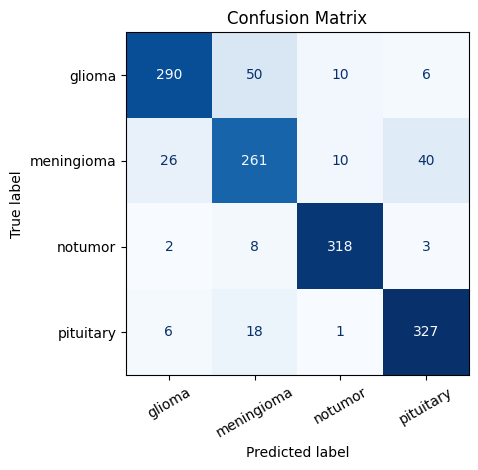

In [ ]:
# Evaluate the model on training and testing data
train_loss, train_accuracy = model.evaluate(train_ds, verbose=0)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

print(f"Training Accuracy: {train_accuracy:.2%}")
print(f"Testing Accuracy: {test_accuracy:.2%}")


# Predict the classes of the testing images
predictions = model.predict(test_ds, verbose=1)

# Compare predicted labels with actual labels
y_true = np.array(test_labels)
y_pred = np.argmax(predictions, axis=1)

# Calculate overall accuracy
accuracy = accuracy_score(y_true, y_pred)

print(f"\nTest Accuracy: {accuracy:.2%}\n")


# Display precision, recall, and F1-score
print(classification_report(
    y_true,
    y_pred,
    labels=range(4),
    target_names=CLASS_NAMES,
    zero_division=0
))


# Calculate the confusion matrix
matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=range(4)
)


# Calculate sensitivity and specificity for each class
for i, name in enumerate(CLASS_NAMES):
    tp = matrix[i, i]
    fn = matrix[i, :].sum() - tp
    fp = matrix[:, i].sum() - tp
    tn = matrix.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if tp + fn else 0
    specificity = tn / (tn + fp) if tn + fp else 0

    print(
        f"{name}: "
        f"Sensitivity = {sensitivity:.2%}, "
        f"Specificity = {specificity:.2%}"
    )


# Display the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=CLASS_NAMES
).plot(cmap="Blues", colorbar=False)

plt.xticks(rotation=30)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Save the Trained Model

The trained neural network is saved in H5 format (.h5), preserving its architecture and learned weights.

This allows the model to be loaded and reused for future predictions without repeating the training process.

The saved file is downloaded for storage and final project submission.

In [ ]:
# Download the model saved after training
model.save("brain_tumor_model.h5")
files.download("brain_tumor_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Test Five New MRI Images

The trained model is tested using five external MRI images that were not included in the original dataset.

Each image undergoes the same preprocessing used during training.

The model predicts the most likely category and displays its confidence score alongside the corresponding MRI image.

This test demonstrates the model's ability to process new images and helps identify limitations when working with different MRI sources.

Saving glioma3.jpeg to glioma3 (1).jpeg
Saving notumor3.jpg to notumor3.jpg
Saving meningioma2.jpeg to meningioma2 (6).jpeg
Saving pituitary2.png to pituitary2 (6).png
Saving notumor2.jpg to notumor2 (6).jpg
Saving glioma2.jpg to glioma2 (8).jpg
Saving meningioma.jpg to meningioma (9).jpg
Saving no tumor.jpeg to no tumor (9).jpeg
Saving pituitary.jpeg to pituitary (9).jpeg
Saving meningioma1.jpeg to meningioma1 (9).jpeg


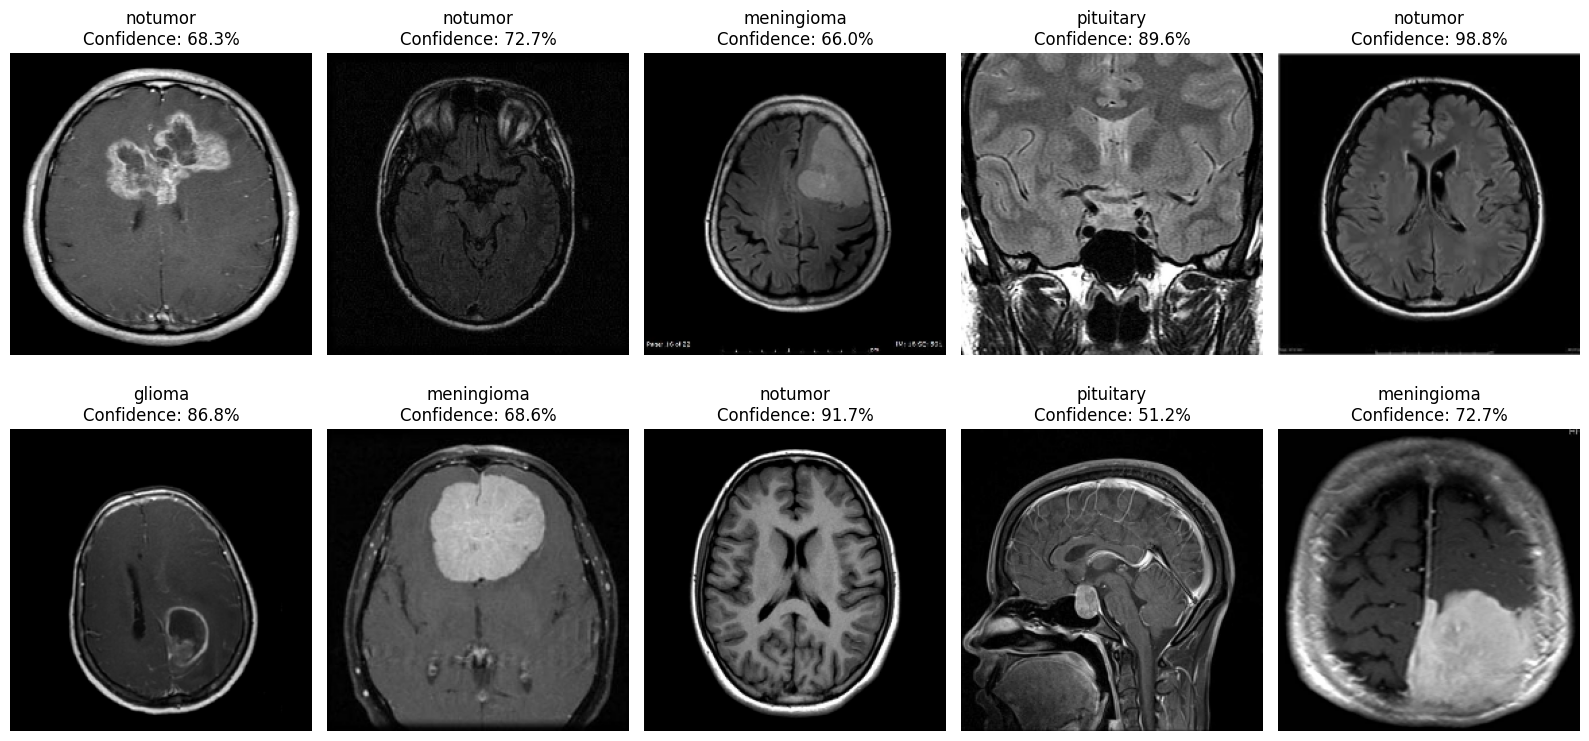

In [ ]:
# Upload external MRI images for testing
uploaded = files.upload()

external_paths = []
external_hashes = set()

# Check file format, image validity, and duplicates
for filename in uploaded:
    if Path(filename).suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    try:
        fingerprint = image_hash(filename)
    except (OSError, ValueError):
        continue

    if fingerprint in known_hashes or fingerprint in external_hashes:
        print(f"Skipped duplicate image: {filename}")
        continue

    external_hashes.add(fingerprint)
    external_paths.append(filename)


# Classify ten external MRI images

if len(external_paths) < 10:
    print(f"At least 10 images required. Accepted: {len(external_paths)}")

else:
    fig, axes = plt.subplots(2, 5, figsize=(16, 8))
    axes = axes.flatten()   # para poder recorrerlos con zip

    for ax, filename in zip(axes, external_paths[:10]):

        # Apply the same image preprocessing used during training
        image = load_image(filename).numpy()

        # Predict the category and confidence score
        scores = model.predict(
            image[np.newaxis, ...],
            verbose=0
        )[0]

        label = CLASS_NAMES[np.argmax(scores)]
        confidence = np.max(scores)

        # Display the image with its prediction
        ax.imshow(image.astype("uint8"))
        ax.set_title(
            f"{label}\nConfidence: {confidence:.1%}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()